# Assignment 5 — Optimization and Learning Rate Schedulers

We use the **Raisin** dataset and the best Assignment 4 configuration: a **7–20–3–1** fully connected network with **L1 λ = 0.7**. We compare mini-batch Gradient Descent, Momentum, and Adam with a constant rate, the tutorial's decay formula, and our Step LR Decay. Run all cells in Colab.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

source = Path("data/raisin.csv")
source = source if source.exists() else "https://raw.githubusercontent.com/agrptec/assignment5-optimization-lr-schedulers/main/data/raisin.csv"
data = pd.read_csv(source)
X = data.drop(columns="Class").to_numpy(dtype=float)
y = data["Class"].map({"Kecimen": 0, "Besni": 1}).to_numpy(dtype=int)
Xtr, Xtmp, ytr, ytmp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=42)
Xval, Xte, yval, yte = train_test_split(Xtmp, ytmp, test_size=0.5, stratify=ytmp, random_state=42)
scaler = StandardScaler()
train_X, train_Y = scaler.fit_transform(Xtr).T, ytr.reshape(1, -1)
val_X, val_Y = scaler.transform(Xval).T, yval.reshape(1, -1)
test_X, test_Y = scaler.transform(Xte).T, yte.reshape(1, -1)
print("Train / validation / test:", train_X.shape, val_X.shape, test_X.shape)


Train / validation / test: (7, 540) (7, 180) (7, 180)


## Model and optimizers

The network and update rules follow the team's tutorial. Every run uses the same initial weights and mini-batch order. L1 is applied to the weight gradients during training.

In [2]:
def initialize_parameters(dims):
    np.random.seed(3)
    p = {}
    for l in range(1, len(dims)):
        p[f"W{l}"] = np.random.randn(dims[l], dims[l-1]) * np.sqrt(2 / dims[l-1])
        p[f"b{l}"] = np.zeros((dims[l], 1))
    return p

def forward(X, p):
    z1 = p["W1"] @ X + p["b1"]
    a1 = np.maximum(0, z1)
    z2 = p["W2"] @ a1 + p["b2"]
    a2 = np.maximum(0, z2)
    z3 = p["W3"] @ a2 + p["b3"]
    a3 = 1 / (1 + np.exp(-z3))
    return a3, (z1, a1, z2, a2)

def backward(X, Y, p, cache, a3):
    z1, a1, z2, a2 = cache
    dz3 = (a3 - Y) / X.shape[1]
    dW3, db3 = dz3 @ a2.T, dz3.sum(axis=1, keepdims=True)
    dz2 = (p["W3"].T @ dz3) * (a2 > 0)
    dW2, db2 = dz2 @ a1.T, dz2.sum(axis=1, keepdims=True)
    dz1 = (p["W2"].T @ dz2) * (a1 > 0)
    dW1, db1 = dz1 @ X.T, dz1.sum(axis=1, keepdims=True)
    return {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2, "dW3": dW3, "db3": db3}

def random_mini_batches(X, Y, size, seed):
    order = np.random.RandomState(seed).permutation(X.shape[1])
    return [(X[:, order[i:i+size]], Y[:, order[i:i+size]])
            for i in range(0, X.shape[1], size)]

def initialize_velocity(p):
    return {"d" + key: np.zeros_like(value) for key, value in p.items()}

def update_parameters_with_gd(p, grads, rate):
    for key in p:
        p[key] -= rate * grads["d" + key]
    return p

def update_parameters_with_momentum(p, grads, v, rate, beta=0.9):
    for key in p:
        name = "d" + key
        v[name] = beta * v[name] + (1 - beta) * grads[name]
        p[key] -= rate * v[name]
    return p, v

def update_parameters_with_adam(p, grads, v, s, t, rate, beta1=0.9, beta2=0.999, eps=1e-8):
    for key in p:
        name = "d" + key
        v[name] = beta1 * v[name] + (1 - beta1) * grads[name]
        s[name] = beta2 * s[name] + (1 - beta2) * grads[name] ** 2
        corrected_v = v[name] / (1 - beta1 ** t)
        corrected_s = s[name] / (1 - beta2 ** t)
        p[key] -= rate * corrected_v / (np.sqrt(corrected_s) + eps)
    return p, v, s

def loss(X, Y, p):
    probabilities, _ = forward(X, p)
    probabilities = np.clip(probabilities, 1e-12, 1 - 1e-12)
    return float(-np.mean(Y * np.log(probabilities) + (1 - Y) * np.log1p(-probabilities)))

def accuracy(X, Y, p):
    probabilities, _ = forward(X, p)
    return float(100 * np.mean((probabilities >= 0.5) == Y))


## Learning-rate schedules

The formula called *exponential decay* in the supplied tutorial is $\eta_e=\eta_0/(1+0.001e)$, mathematically an **inverse-time** schedule. Our Step LR Decay is $\eta_e=\eta_0(0.7)^{\lfloor e/1000\rfloor}$.

In [3]:
def tutorial_decay(initial_rate, epoch):
    return initial_rate / (1 + 0.001 * epoch)

def custom_step_decay(initial_rate, epoch):
    return initial_rate * 0.7 ** (epoch // 1000)

def learning_rate(initial_rate, epoch, scheduler):
    if scheduler == "constant":
        return initial_rate
    if scheduler == "tutorial_decay":
        return tutorial_decay(initial_rate, epoch)
    return custom_step_decay(initial_rate, epoch)

def train(optimizer, scheduler, initial_rate, epochs=5000):
    p = initialize_parameters([7, 20, 3, 1])
    v = initialize_velocity(p) if optimizer in ("momentum", "adam") else None
    s = initialize_velocity(p) if optimizer == "adam" else None
    t, history = 0, {"epoch": [], "train_loss": [], "val_loss": []}
    for epoch in range(epochs):
        rate = learning_rate(initial_rate, epoch, scheduler)
        for batch_X, batch_Y in random_mini_batches(train_X, train_Y, 64, 11 + epoch):
            a3, cache = forward(batch_X, p)
            grads = backward(batch_X, batch_Y, p, cache, a3)
            for layer in (1, 2, 3):
                grads[f"dW{layer}"] += (0.7 / train_X.shape[1]) * np.sign(p[f"W{layer}"])
            if optimizer == "gd":
                p = update_parameters_with_gd(p, grads, rate)
            elif optimizer == "momentum":
                p, v = update_parameters_with_momentum(p, grads, v, rate)
            else:
                t += 1
                p, v, s = update_parameters_with_adam(p, grads, v, s, t, rate)
        if epoch == 0 or (epoch + 1) % 50 == 0:
            history["epoch"].append(epoch + 1)
            history["train_loss"].append(loss(train_X, train_Y, p))
            history["val_loss"].append(loss(val_X, val_Y, p))
    return p, pd.DataFrame(history)


## Results

All nine experiments use 5,000 epochs and batch size 64. Initial learning rates follow the tutorial's practical settings: 0.1 for GD/Momentum and 0.01 for Adam. We compare final validation loss and accuracy; the test set is used only after model selection.

In [4]:
initial_rates = {"gd": 0.1, "momentum": 0.1, "adam": 0.01}
schedulers = ("constant", "tutorial_decay", "step")
rows, histories, models = [], {}, {}
for optimizer, initial_rate in initial_rates.items():
    for scheduler in schedulers:
        p, history = train(optimizer, scheduler, initial_rate)
        histories[(optimizer, scheduler)] = history
        models[(optimizer, scheduler)] = p
        rows.append({"optimizer": optimizer, "scheduler": scheduler,
                     "validation_loss": history.val_loss.iloc[-1],
                     "validation_accuracy_pct": accuracy(val_X, val_Y, p)})
summary = pd.DataFrame(rows).sort_values("validation_loss").reset_index(drop=True)
display(summary.round(4))


,optimizer,scheduler,validation_loss,validation_accuracy_pct
0,adam,constant,0.5508,85.5556
1,gd,tutorial_decay,0.5534,85.5556
2,momentum,tutorial_decay,0.5588,86.6667
3,adam,step,0.5593,86.1111
4,momentum,step,0.5640,86.6667
5,momentum,constant,0.5707,86.1111
6,gd,step,0.5731,86.6667
7,adam,tutorial_decay,0.5772,84.4444
8,gd,constant,0.5821,85.5556


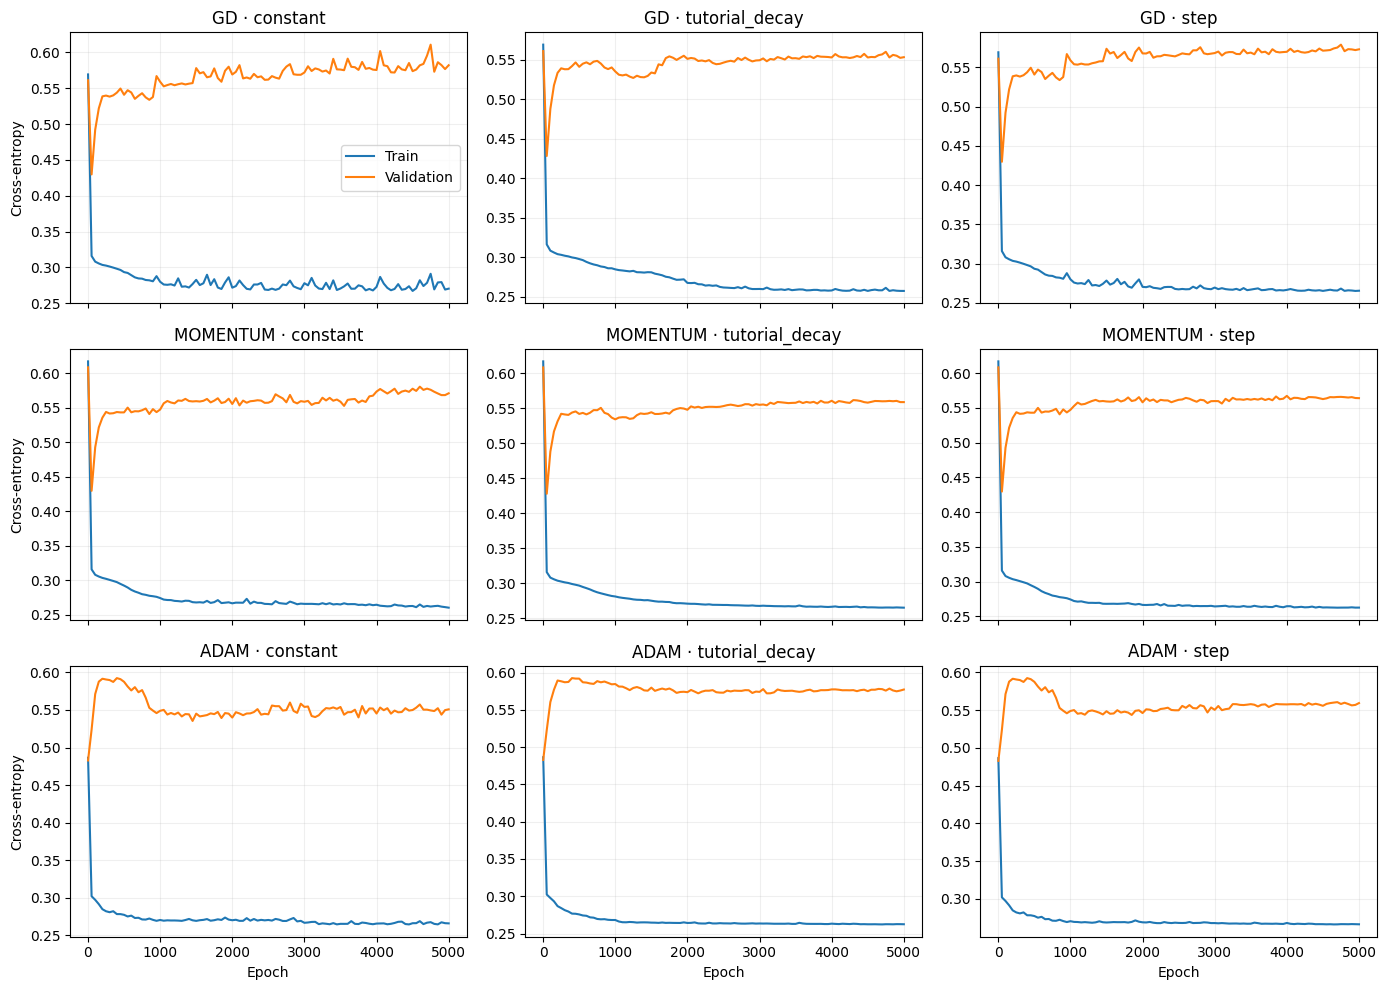

Selected by validation loss: ADAM / constant
Validation loss: 0.5508; accuracy: 85.56%
Held-out test accuracy: 87.22%


In [5]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10), sharex=True)
for row, optimizer in enumerate(initial_rates):
    for col, scheduler in enumerate(schedulers):
        history = histories[(optimizer, scheduler)]
        ax = axes[row, col]
        ax.plot(history.epoch, history.train_loss, label="Train")
        ax.plot(history.epoch, history.val_loss, label="Validation")
        ax.set_title(f"{optimizer.upper()} · {scheduler}")
        ax.grid(alpha=0.2)
        if row == 2: ax.set_xlabel("Epoch")
        if col == 0: ax.set_ylabel("Cross-entropy")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

best = summary.iloc[0]
selected = models[(best.optimizer, best.scheduler)]
print(f"Selected by validation loss: {best.optimizer.upper()} / {best.scheduler}")
print(f"Validation loss: {best.validation_loss:.4f}; accuracy: {best.validation_accuracy_pct:.2f}%")
print(f"Held-out test accuracy: {accuracy(test_X, test_Y, selected):.2f}%")


**Interpretation.** Compare each optimizer's validation curve with its constant-rate run. The scheduler that gives the best validation loss need not give the best classification accuracy, because cross-entropy also reflects prediction confidence. The accompanying PDF discusses the measured results and limitations. Dataset: Çinar, Koklu & Tasdemir (2020), [UCI Raisin](https://archive.ics.uci.edu/dataset/850/raisin), CC BY 4.0.